In [1]:
import xarray as xr
import numpy as np
import cftime
import xesmf as xe
import TCs
import matplotlib.pyplot as plt
from scipy.stats import linregress
from scipy import stats
from scipy.signal import cheby1, filtfilt
from scipy.stats import ttest_ind
import pandas as pd

import matplotlib.gridspec as gridspec
from matplotlib.patches import Rectangle
import cartopy.crs as ccrs
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
from matplotlib.ticker import ScalarFormatter
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import matplotlib as mpl

import cartopy.feature as cfeature
from cartopy.crs import PlateCarree, Robinson
from matplotlib.colors import TwoSlopeNorm

import dask
dask.config.set({'array.slicing.split_large_chunks': True})
import Plot

In [2]:
import matplotlib.transforms as mtransforms

def add_lat_labels(ax, lats=(-60, -30, 0, 30, 60), pad=3, fontsize=8):
    lon_0 = ax.projection.proj4_params.get('lon_0', 0.0)
    trans = mtransforms.offset_copy(ax.transData, fig=ax.figure,
                                    x=-pad, y=0, units='points')
    for lat in lats:
        x, y = ax.projection.transform_point(lon_0 - 179.99, lat, ccrs.PlateCarree())
        suffix = 'N' if lat > 0 else 'S' if lat < 0 else ''
        ax.text(x, y, f'{abs(lat)}°{suffix}', transform=trans,
                ha='right', va='center', fontsize=fontsize, clip_on=False)

def add_graticule(ax, lat_labels=False):
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(), draw_labels=False,
        linewidth=0.6, color='gray', alpha=0.8, linestyle=':', zorder=20
    )
    gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
    gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))
    gl.top_labels = gl.right_labels= gl.left_labels = False
    gl.bottom_labels = lat_labels
    gl.xlabel_style = {'size': 8}
    gl.ylabel_style = {'size': 8}
    gl.xpadding = 1.5 
    return gl

In [5]:
ds = xr.open_dataset("Figure8.nc")

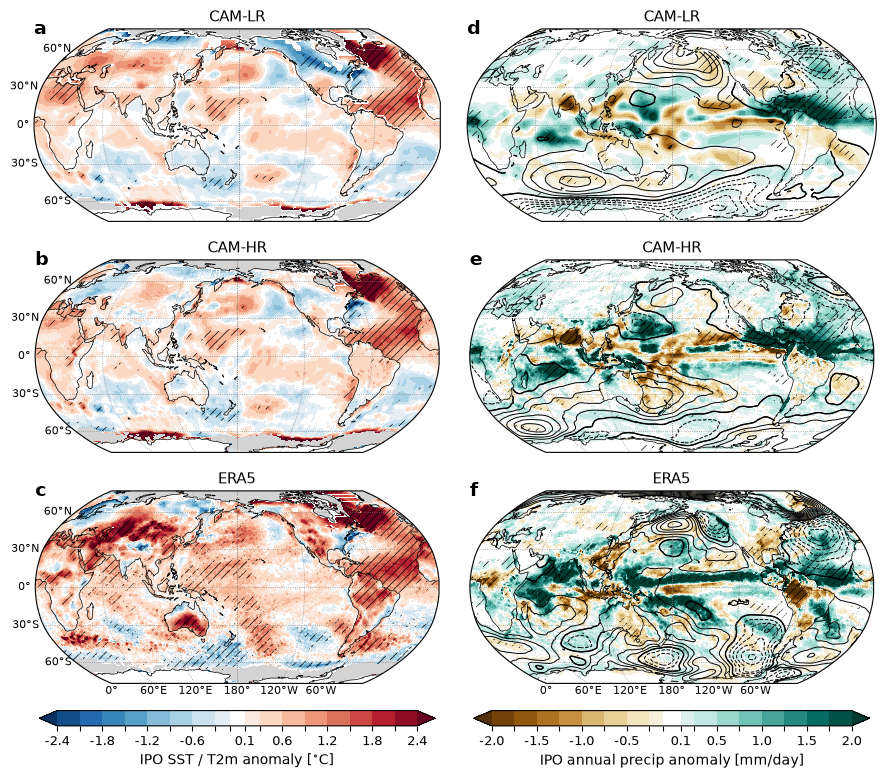

In [6]:
fig, axs = plt.subplots(ncols=2, nrows=3, figsize=(11,8.5),
                       subplot_kw={"projection": ccrs.Robinson(central_longitude=180)})
plt.subplots_adjust(wspace=0.04)

(cmap1, levels1, norm1) = Plot.def_colormap(max=2.4, white=0.1, interval=0.3, cmap='RdBu_r')
(cmap2, levels2, norm2) = Plot.def_colormap(max=2.0, white=0.1, interval=0.25, cmap='BrBG')

sig_thr = 0
var1 = 'SST'; var2 = 'TREFHT'
var3 = 'PRECT'; var4 = 'PS'
internal='AMO'
mpl.rcParams['hatch.linewidth']=0.5

ds1 = [    # SST & PRECT
    (ds.var1_sdcam, ds.var1_sig_sdcam, f"CAM-LR", 'sdcam'), 
    (ds.var3_sdcam, ds.var3_sig_sdcam, f"CAM-LR", 'sdcam'), 
    (ds.var1_hicam, ds.var1_sig_hicam, f"CAM-HR", 'hicam'), 
    (ds.var3_hicam, ds.var3_sig_hicam, f"CAM-HR", 'hicam'),
    (ds.var1_era5, ds.var1_sig_era5, f"ERA5" ,'era5'), 
    (ds.var3_era5, ds.var3_sig_era5, f"ERA5" ,'era5'), 
]

ds2 = [  # TREFHT & PS(on land)
    (ds.var2_sdcam, ds.var2_sig_sdcam, f"CAM-LR", 'sdcam'), 
    (ds.var4_sdcam, ds.var4_sig_sdcam, f"CAM-LR", 'sdcam'), 
    (ds.var2_hicam, ds.var2_sig_hicam, f"CAM-HR", 'hicam'), 
    (ds.var4_hicam, ds.var4_sig_hicam, f"CAM-HR", 'hicam'),
    (ds.var2_era5, ds.var2_sig_era5, f"ERA5" ,'era5'), 
    (ds.var4_era5, ds.var4_sig_era5, f"ERA5" ,'era5'), 
]
numbers = ['a', 'd', 'b', 'e', 'c', 'f']

icemask_ds = [
    ds.icemask_sdcam, ds.icemask_hicam, ds.icemask_era5
]
landmask_ds = [
    ds.landmask_sdcam, ds.landmask_hicam, ds.landmask_era5
]

for ii in range(6):
    ax = axs[ii//2][ii%2]
    ds1_now = ds1[ii][0]
    sig1_now = ds1[ii][1]
    ds2_now = ds2[ii][0]
    sig2_now = ds2[ii][1]

    if ii%2==0:
        icemask_now = icemask_ds[ii//2]
        
        cf1 = ds1_now.where(icemask_now==0).plot.contourf(
            ax=ax, transform=ccrs.PlateCarree(), levels=levels1, cmap=cmap1, norm = norm1,
            extend="both", add_colorbar=False
        )
        mask_sig = (ds1_now>sig_thr) | (ds1_now<-sig_thr)
        ax.contourf(
            ds1_now[f"lon_{ds1[ii][3]}"], ds1_now[f"lat_{ds1[ii][3]}"], sig1_now.where(mask_sig).where(icemask_now==0).astype(float),
            levels=[0.5, 1.0], hatches=["////"], colors="none", transform=ccrs.PlateCarree()
        )
        ds2_now.where(icemask_now==0).plot.contourf(
            ax=ax, transform=ccrs.PlateCarree(), levels=levels1, cmap=cmap1, norm = norm1,
            extend="both", add_colorbar=False
        )
        mask_sig = (ds2_now>sig_thr) | (ds2_now<-sig_thr)
        ax.contourf(
            ds2_now[f"lon_{ds2[ii][3]}"], ds2_now[f"lat_{ds2[ii][3]}"], sig2_now.where(mask_sig).where(icemask_now==0).astype(float),
            levels=[0.5, 1.0], hatches=["////"], colors="none", transform=ccrs.PlateCarree()
        )
        my_icemask = xr.where(icemask_now==0, np.nan, 1.0)
        my_icemask.where(landmask_ds[ii//2]==0).plot.contourf(
            ax=ax, transform=ccrs.PlateCarree(), levels=[0.5, 1.5], 
            colors=["lightgrey"], add_colorbar=False)
    else:
        cf2 = ds1_now.plot.contourf(
            ax=ax, transform=ccrs.PlateCarree(), levels=levels2, cmap=cmap2, norm = norm2,
            extend="both", add_colorbar=False
        )
        mask_sig = (ds1_now>sig_thr) | (ds1_now<-sig_thr)
        ax.contourf(
            ds1_now[f"lon_{ds1[ii][3]}"], ds1_now[f"lat_{ds1[ii][3]}"], sig1_now.where(mask_sig).astype(float),
            levels=[0.5, 1.0], hatches=["////"], colors="none", transform=ccrs.PlateCarree()
        )
        ds2_now.plot.contour(
            ax=ax, transform=ccrs.PlateCarree(), colors='black', levels=np.arange(-600, 600+60, 60), 
            linewidths=0.7, add_colorbar=False
        )
        ds2_now.plot.contour(
            ax=ax, transform=ccrs.PlateCarree(), colors='black', levels=[0], 
            linewidths=1.0, add_colorbar=False
        )
    ax.coastlines(linewidth=0.5)
    ax.annotate(numbers[ii], xy=(0, 1.05), xycoords='axes fraction', fontsize=14, fontweight='bold', ha='left', va='top')
    ax.set_title(None)
    ax.text(0.5, 1.02, ds1[ii][2], transform=ax.transAxes, fontsize=11, ha='center', va='bottom')
    add_graticule(ax, lat_labels=(ii//2==2))
    if ii%2==0:
        add_lat_labels(ax)

# colorbar
cax = fig.add_axes([0.135, 0.06, 0.36, 0.018])  # [left, bottom, width, height] in figure coords
cbar = fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap1, norm=norm1),
                    cax=cax, orientation='horizontal', ticks=levels1[levels1 != 0], 
                    extend='both', spacing='proportional', label=r'IPO SST / T2m anomaly [$^{\circ}$C]')
major_ticks = [-2.4, -1.8, -1.2, -0.6, 0.1, 0.6, 1.2, 1.8, 2.4]
major_labels = [ '' if t not in major_ticks else f'{t:.1f}' for t in levels1[levels1 != 0]]
cbar.ax.minorticks_off()
cbar.ax.set_xticklabels(major_labels, minor=False)
cbar.ax.tick_params(labelsize=9)


cax = fig.add_axes([0.53, 0.06, 0.36, 0.018])  # [left, bottom, width, height] in figure coords
cbar = fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap2, norm=norm2),
                    cax=cax, orientation='horizontal', ticks=levels2[levels2 != 0], 
                    extend='both', spacing='proportional', label=r'IPO annual precip anomaly [mm/day]')
major_ticks = [-2.0, -1.5, -1.0, -0.5, 0.1, 0.5, 1.0, 1.5, 2.0]
major_labels = [ '' if t not in major_ticks else f'{t:.1f}' for t in levels2[levels2 != 0]]
cbar.ax.minorticks_off()
cbar.ax.set_xticklabels(major_labels, minor=False)
cbar.ax.tick_params(labelsize=9)

# plt.savefig(f'Figure8.png', bbox_inches='tight', dpi=300)